# TCC - SEGMENTAÇÃO DE MASSAS EM REGIÕES DE INTERESSE DE MAMOGRAFIAS

> No Colab, escolha **Ambiente de execução → Alterar tipo de ambiente de execução → GPU T4** e execute as células na ordem.

In [1]:
# 1) Montar o Google Drive e definir os parâmetros
from google.colab import drive
drive.mount('/content/gdrive')

from pathlib import Path

DATASET_DIR = Path('/content/gdrive/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed')
DRIVE_IMAGES_DIR = DATASET_DIR / 'images'
DRIVE_MASKS_DIR = DATASET_DIR / 'masks'
RUN_DIR = DATASET_DIR / 'resultados_roi_massas'
RUN_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
ROI_SIZE = 512
ROI_SCALE = 2.0
MIN_CONTEXT = 64
BATCH_SIZE = 4
EPOCHS = 70
LEARNING_RATE = 1e-4
USE_LOCAL_CACHE = True
RESUME_FROM_BEST = True
SAVE_TEST_PREDICTIONS = 30

assert DRIVE_IMAGES_DIR.is_dir(), f'Pasta não encontrada: {DRIVE_IMAGES_DIR}'
assert DRIVE_MASKS_DIR.is_dir(), f'Pasta não encontrada: {DRIVE_MASKS_DIR}'
print('Dataset:', DATASET_DIR)
print('Resultados ROI:', RUN_DIR)

Mounted at /content/gdrive
Dataset: /content/gdrive/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed
Resultados ROI: /content/gdrive/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas


In [ ]:
# 2) Importações, GPU, precisão mista e reprodutibilidade
import os, re, gc, json, math, random, shutil, warnings
from functools import lru_cache

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings('ignore', category=UserWarning)
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('GPU(s):', gpus)
if not gpus:
    raise RuntimeError('GPU não encontrada. Ative uma GPU nas configurações do Colab.')

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
print('Política numérica:', mixed_precision.global_policy())

TensorFlow: 2.20.0
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Política numérica: <DTypePolicy "mixed_float16">


## Pareamento e auditoria

Os caminhos internos dos CSVs vieram de outro computador (`D:\...`). Por isso, o notebook não confia nesses caminhos: ele pareia `images/` e `masks/` pelo nome do arquivo. Os CSVs originais permanecem preservados.

In [ ]:
# 3) Parear imagens e máscaras pelo nome
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}

def index_images(folder):
    return {
        p.name: p
        for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    }

drive_images = index_images(DRIVE_IMAGES_DIR)
drive_masks = index_images(DRIVE_MASKS_DIR)
common_names = sorted(set(drive_images) & set(drive_masks))
only_images = sorted(set(drive_images) - set(drive_masks))
only_masks = sorted(set(drive_masks) - set(drive_images))

print(f'Imagens: {len(drive_images)} | Máscaras: {len(drive_masks)} | Pares: {len(common_names)}')
print(f'Sem máscara: {len(only_images)} | Sem imagem: {len(only_masks)}')
assert common_names, 'Nenhum par foi encontrado.'
assert len(common_names) >= 100, 'Poucos pares encontrados; confira DATASET_DIR.'

def parse_name(filename):
    stem = Path(filename).stem.upper()
    patient_match = re.search(r'MASS_P_(\d+)', stem)
    pathology_match = re.search(r'_([BM])_\d+$', stem)
    view_match = re.search(r'_(CC|MLO)_', stem)
    side_match = re.search(r'_(LEFT|RIGHT)_', stem)
    return {
        'patient': f'P_{patient_match.group(1)}' if patient_match else stem,
        'pathology': pathology_match.group(1) if pathology_match else 'UNK',
        'view': view_match.group(1) if view_match else 'UNK',
        'side': side_match.group(1) if side_match else 'UNK',
    }

records = []
for name in common_names:
    records.append({
        'filename': name,
        'image_path': str(drive_images[name]),
        'mask_path': str(drive_masks[name]),
        **parse_name(name),
    })

df = pd.DataFrame(records)
display(df.head())
display(pd.crosstab(df['pathology'], df['view'], margins=True))
print('Pacientes únicos:', df['patient'].nunique())

Imagens: 1318 | Máscaras: 1321 | Pares: 1318
Sem máscara: 0 | Sem imagem: 3


,filename,image_path,mask_path,patient,pathology,view,side
0,MASS_P_00001_LEFT_CC_M_1.jpg,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,P_00001,M,CC,LEFT
1,MASS_P_00001_LEFT_MLO_M_1.jpg,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,P_00001,M,MLO,LEFT
2,MASS_P_00004_LEFT_CC_B_1.jpg,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,P_00004,B,CC,LEFT
3,MASS_P_00004_LEFT_MLO_B_1.jpg,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,P_00004,B,MLO,LEFT
4,MASS_P_00004_RIGHT_MLO_B_1.jpg,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,/content/drive/MyDrive/2026_TCC_JoaoPedro_Segm...,P_00004,B,MLO,RIGHT


view,CC,MLO,All
pathology,,,
B,311,370,681
M,296,341,637
All,607,711,1318


Pacientes únicos: 691


In [ ]:
# 4) Cache local opcional: reduz o gargalo de leitura do Google Drive
if USE_LOCAL_CACHE:
    local_root = Path('/content/cbis_ddsm_mass_cache')
    local_images = local_root / 'images'
    local_masks = local_root / 'masks'
    local_images.mkdir(parents=True, exist_ok=True)
    local_masks.mkdir(parents=True, exist_ok=True)

    total_bytes = sum(p.stat().st_size for p in drive_images.values()) + sum(p.stat().st_size for p in drive_masks.values())
    free_bytes = shutil.disk_usage('/content').free
    print(f'Tamanho aproximado: {total_bytes/2**30:.2f} GB | Livre no Colab: {free_bytes/2**30:.2f} GB')

    if total_bytes * 1.25 < free_bytes:
        print('Copiando/atualizando cache local...')
        shutil.copytree(DRIVE_IMAGES_DIR, local_images, dirs_exist_ok=True)
        shutil.copytree(DRIVE_MASKS_DIR, local_masks, dirs_exist_ok=True)
        image_index = index_images(local_images)
        mask_index = index_images(local_masks)
        if set(common_names).issubset(image_index) and set(common_names).issubset(mask_index):
            df['image_path'] = df['filename'].map(lambda n: str(image_index[n]))
            df['mask_path'] = df['filename'].map(lambda n: str(mask_index[n]))
            print('Cache local pronto.')
        else:
            print('Cache incompleto; usando os arquivos diretamente do Drive.')
    else:
        print('Espaço insuficiente para cache; usando diretamente o Drive.')
else:
    print('Cache local desativado.')

Tamanho aproximado: 2.46 GB | Livre no Colab: 188.46 GB
Copiando/atualizando cache local...
Cache local pronto.


In [ ]:
# 5) Auditoria das dimensões e máscaras
audit_rows = []
invalid = []

for row in tqdm(df.itertuples(index=False), total=len(df), desc='Auditando'):
    image = cv2.imread(row.image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE)
    if image is None or mask is None:
        invalid.append((row.filename, 'falha de leitura'))
        continue
    if image.shape != mask.shape:
        invalid.append((row.filename, f'dimensões diferentes: {image.shape} x {mask.shape}'))
        continue
    binary = mask > 127
    if not binary.any():
        invalid.append((row.filename, 'máscara vazia'))
        continue
    ys, xs = np.where(binary)
    audit_rows.append({
        'filename': row.filename,
        'height': image.shape[0],
        'width': image.shape[1],
        'mask_fraction': float(binary.mean()),
        'bbox_height': int(ys.max() - ys.min() + 1),
        'bbox_width': int(xs.max() - xs.min() + 1),
    })

audit_df = pd.DataFrame(audit_rows)
print('Pares válidos:', len(audit_df), '| Inválidos:', len(invalid))
if invalid:
    display(pd.DataFrame(invalid, columns=['filename', 'problem']).head(20))
    valid_names = set(audit_df['filename'])
    df = df[df['filename'].isin(valid_names)].reset_index(drop=True)

display(audit_df[['height','width','mask_fraction','bbox_height','bbox_width']].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
audit_df.to_csv(RUN_DIR / 'auditoria_dataset.csv', index=False)
df.to_csv(RUN_DIR / 'manifesto_pares_validos.csv', index=False)

Auditando:   0%|          | 0/1318 [00:00<?, ?it/s]

Pares válidos: 1253 | Inválidos: 65


,filename,problem
0,MASS_P_00059_LEFT_CC_M_1.jpg,"dimensões diferentes: (5386, 3601) x (4686, 3133)"
1,MASS_P_00059_LEFT_MLO_M_1.jpg,"dimensões diferentes: (5386, 3466) x (4686, 3016)"
2,MASS_P_00108_LEFT_CC_B_1.jpg,"dimensões diferentes: (5386, 3391) x (4686, 2951)"
3,MASS_P_00108_LEFT_MLO_B_1.jpg,"dimensões diferentes: (5386, 3436) x (4686, 2990)"
4,MASS_P_00279_LEFT_CC_B_1.jpg,"dimensões diferentes: (5386, 3691) x (4686, 3212)"
5,MASS_P_00304_LEFT_MLO_B_1.jpg,"dimensões diferentes: (5221, 3391) x (4543, 2951)"
6,MASS_P_00384_RIGHT_CC_B_1.jpg,"dimensões diferentes: (5296, 3061) x (4608, 2664)"
7,MASS_P_00384_RIGHT_MLO_B_1.jpg,"dimensões diferentes: (5296, 3436) x (4608, 2990)"
8,MASS_P_00423_RIGHT_CC_M_1.jpg,"dimensões diferentes: (5026, 2131) x (4373, 1854)"
9,MASS_P_00436_LEFT_CC_B_1.jpg,"dimensões diferentes: (4966, 3061) x (4321, 2664)"


,height,width,mask_fraction,bbox_height,bbox_width
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,5296.385475,3156.000798,0.005161,330.218675,331.466081
std,675.991646,552.987120,0.005194,141.351645,141.137500
min,4136.000000,1786.000000,0.000175,86.000000,55.000000
10%,4568.000000,2521.000000,0.001275,190.000000,192.000000
25%,4696.000000,2744.000000,0.002081,237.000000,239.000000
50%,5281.000000,3024.000000,0.003549,302.000000,300.000000
75%,5824.000000,3632.000000,0.006149,384.000000,386.000000
90%,6235.000000,3961.000000,0.010493,514.000000,505.000000
95%,6577.000000,4072.000000,0.015066,595.400000,606.800000


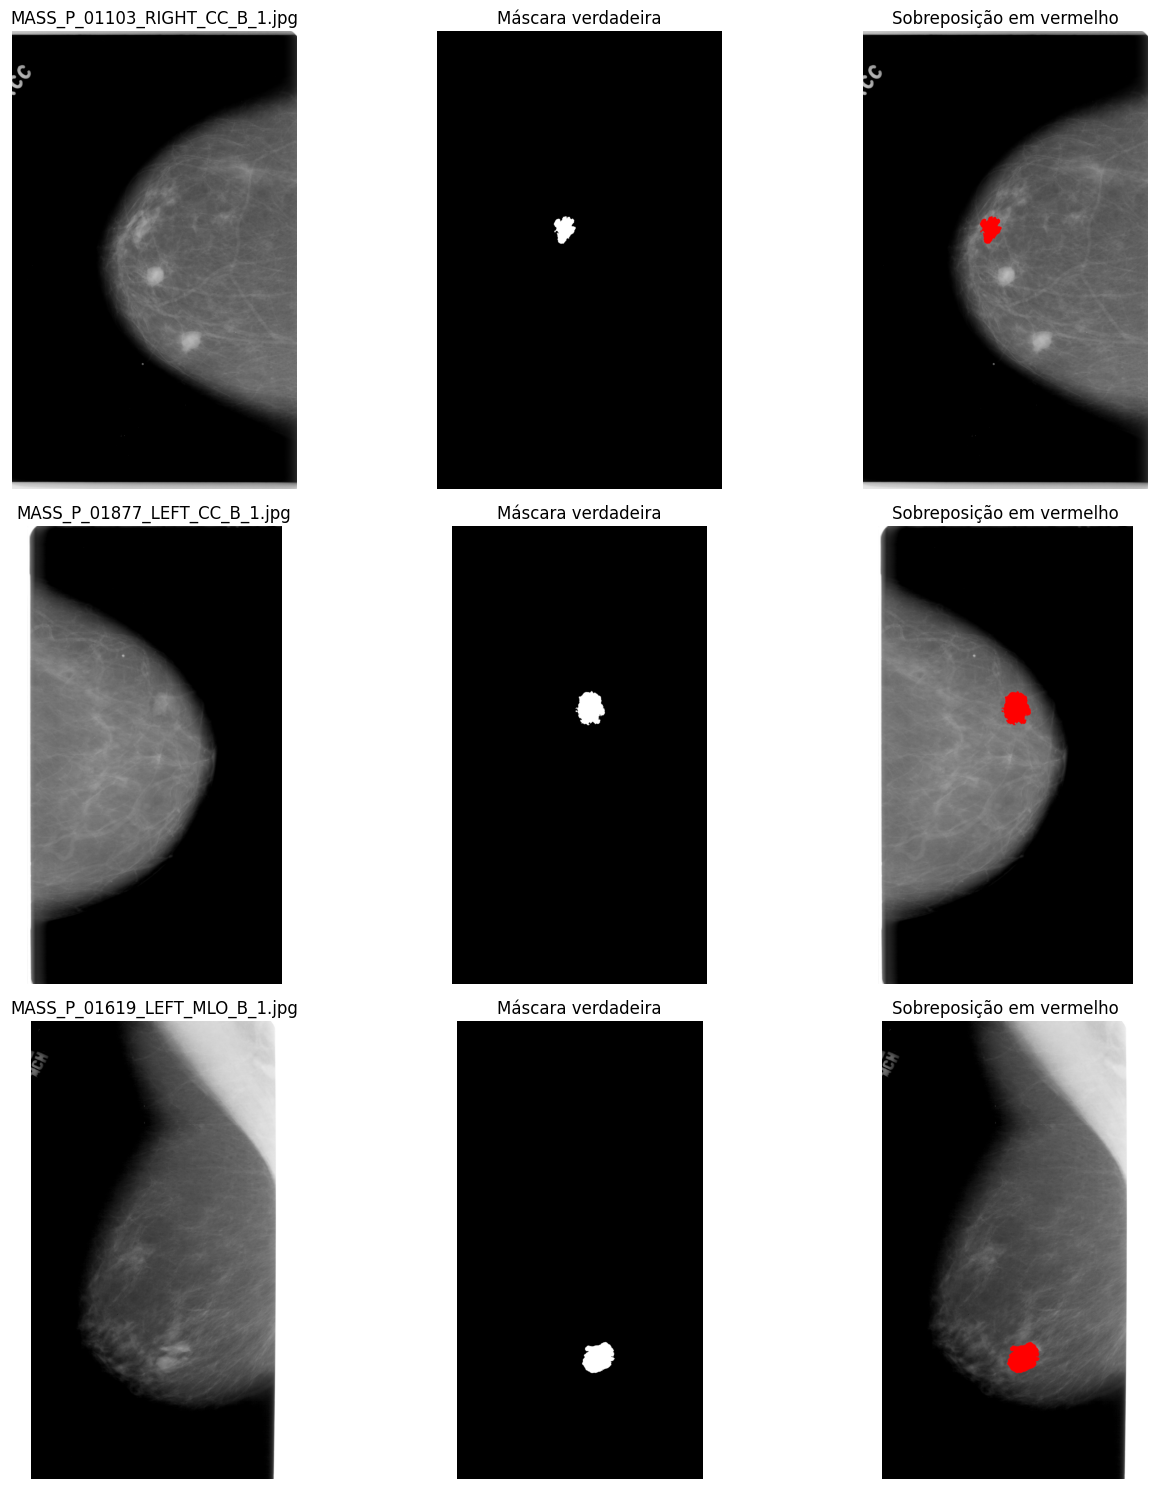

In [ ]:
# 6) Visualizar alguns pares para checar alinhamento
def show_pairs(dataframe, n=4, seed=SEED):
    sample = dataframe.sample(min(n, len(dataframe)), random_state=seed)
    fig, axes = plt.subplots(len(sample), 3, figsize=(14, 5*len(sample)))
    if len(sample) == 1:
        axes = np.expand_dims(axes, 0)
    for axrow, row in zip(axes, sample.itertuples(index=False)):
        image = cv2.imread(row.image_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE) > 127
        overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        overlay[mask] = (255, 0, 0)
        axrow[0].imshow(image, cmap='gray'); axrow[0].set_title(row.filename)
        axrow[1].imshow(mask, cmap='gray'); axrow[1].set_title('Máscara verdadeira')
        axrow[2].imshow(overlay); axrow[2].set_title('Sobreposição em vermelho')
        for ax in axrow: ax.axis('off')
    plt.tight_layout()

show_pairs(df, n=3)

In [ ]:
# 7) Divisão 70%/15%/15% por paciente, estratificada por patologia
patient_df = (
    df.groupby('patient', as_index=False)
      .agg(pathology=('pathology', lambda s: 'M' if (s == 'M').any() else ('B' if (s == 'B').any() else 'UNK')))
)

def safe_split(frame, test_size, seed):
    strat = frame['pathology'] if frame['pathology'].value_counts().min() >= 2 else None
    return train_test_split(frame, test_size=test_size, random_state=seed, stratify=strat)

train_patients, temp_patients = safe_split(patient_df, 0.30, SEED)
val_patients, test_patients = safe_split(temp_patients, 0.50, SEED + 1)

patient_to_split = {p: 'train' for p in train_patients['patient']}
patient_to_split.update({p: 'val' for p in val_patients['patient']})
patient_to_split.update({p: 'test' for p in test_patients['patient']})
df['split'] = df['patient'].map(patient_to_split)

train_df = df[df.split == 'train'].reset_index(drop=True)
val_df = df[df.split == 'val'].reset_index(drop=True)
test_df = df[df.split == 'test'].reset_index(drop=True)

assert set(train_df.patient).isdisjoint(val_df.patient)
assert set(train_df.patient).isdisjoint(test_df.patient)
assert set(val_df.patient).isdisjoint(test_df.patient)

summary_split = df.groupby('split').agg(images=('filename','size'), patients=('patient','nunique'))
display(summary_split)
display(pd.crosstab(df['split'], df['pathology'], margins=True))
df.to_csv(RUN_DIR / 'divisao_por_paciente.csv', index=False)

,images,patients
split,,
test,181,99
train,882,459
val,190,99


pathology,B,M,All
split,,,
test,88,93,181
train,449,433,882
val,95,95,190
All,632,621,1253


In [ ]:
# 8) Normalização e recorte determinístico da ROI
def enhance_mammogram(image_u8):
    image_u8 = np.asarray(image_u8, dtype=np.uint8)
    nonzero = image_u8[image_u8 > 0]
    if nonzero.size:
        lo, hi = np.percentile(nonzero, [1.0, 99.5])
        if hi > lo:
            image_u8 = np.clip((image_u8.astype(np.float32)-lo)*255.0/(hi-lo), 0, 255).astype(np.uint8)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(image_u8)

def roi_bounds(mask, scale=ROI_SCALE, min_context=MIN_CONTEXT):
    ys, xs = np.where(mask > 0)
    if not len(ys):
        raise ValueError('Máscara vazia')
    y1, y2, x1, x2 = ys.min(), ys.max()+1, xs.min(), xs.max()+1
    lesion_side = max(y2-y1, x2-x1)
    side = int(max(lesion_side*scale, lesion_side+2*min_context))
    cy, cx = (y1+y2)//2, (x1+x2)//2
    return cy, cx, side

def square_crop(array, cy, cx, side):
    half = side//2
    y1, x1, y2, x2 = cy-half, cx-half, cy-half+side, cx-half+side
    pt, pl, pb, pr = max(0,-y1), max(0,-x1), max(0,y2-array.shape[0]), max(0,x2-array.shape[1])
    if pt or pl or pb or pr:
        array = cv2.copyMakeBorder(array, pt, pb, pl, pr, cv2.BORDER_CONSTANT, value=0)
        y1, y2, x1, x2 = y1+pt, y2+pt, x1+pl, x2+pl
    return array[y1:y2, x1:x2]

@lru_cache(maxsize=48)
def load_roi_pair(image_path, mask_path):
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if image is None or mask is None or image.shape != mask.shape:
        raise ValueError(f'Par inválido: {image_path}')
    mask = mask > 127
    cy, cx, side = roi_bounds(mask)
    image_roi = square_crop(enhance_mammogram(image), cy, cx, side)
    mask_roi = square_crop(mask.astype(np.uint8), cy, cx, side)
    image_roi = cv2.resize(image_roi, (ROI_SIZE, ROI_SIZE), interpolation=cv2.INTER_AREA)
    mask_roi = cv2.resize(mask_roi, (ROI_SIZE, ROI_SIZE), interpolation=cv2.INTER_NEAREST) > 0
    return image_roi, mask_roi.astype(np.uint8), (cy, cx, side)

In [ ]:
# 9) Gerador de ROIs; validação e teste permanecem fixos
class ROISequence(tf.keras.utils.Sequence):
    def __init__(self, dataframe, batch_size, training, seed=SEED):
        super().__init__()
        self.df = dataframe.reset_index(drop=True)
        self.batch_size = batch_size
        self.training = training
        self.seed = seed
        self.epoch = 0
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.indices)/self.batch_size)

    def on_epoch_end(self):
        if self.training:
            np.random.default_rng(self.seed+self.epoch).shuffle(self.indices)
            self.epoch += 1

    @staticmethod
    def augment(image, mask, rng):
        if rng.random() < .5:
            image, mask = np.fliplr(image), np.fliplr(mask)
        if rng.random() < .7:
            angle, zoom = float(rng.uniform(-12,12)), float(rng.uniform(.92,1.08))
            M = cv2.getRotationMatrix2D((ROI_SIZE/2,ROI_SIZE/2), angle, zoom)
            image = cv2.warpAffine(image, M, (ROI_SIZE,ROI_SIZE), flags=cv2.INTER_LINEAR)
            mask = cv2.warpAffine(mask, M, (ROI_SIZE,ROI_SIZE), flags=cv2.INTER_NEAREST)
        if rng.random() < .6:
            image = np.clip(image.astype(np.float32)*rng.uniform(.88,1.12)+rng.uniform(-12,12),0,255)
        return np.ascontiguousarray(image), np.ascontiguousarray(mask)

    def __getitem__(self, batch_index):
        ids = self.indices[batch_index*self.batch_size:(batch_index+1)*self.batch_size]
        xs, ys = [], []
        for position, row_idx in enumerate(ids):
            row = self.df.iloc[int(row_idx)]
            image, mask, _ = load_roi_pair(row.image_path, row.mask_path)
            if self.training:
                rng = np.random.default_rng(self.seed+self.epoch*100003+batch_index*101+position)
                image, mask = self.augment(image, mask, rng)
            # EfficientNet do Keras recebe escala 0..255 e faz a normalização internamente.
            xs.append(np.repeat(image[...,None], 3, axis=-1).astype(np.float32))
            ys.append((mask>0).astype(np.float32)[...,None])
        return np.asarray(xs,np.float32), np.asarray(ys,np.float32)

train_seq = ROISequence(train_df, BATCH_SIZE, training=True, seed=SEED)
val_seq = ROISequence(val_df, BATCH_SIZE, training=False, seed=SEED+1000)
x_check, y_check = train_seq[0]
print('Batch ROI:', x_check.shape, y_check.shape, 'fração positiva:', y_check.mean())

Batch ROI: (4, 512, 512, 3) (4, 512, 512, 1) fração positiva: 0.16168404


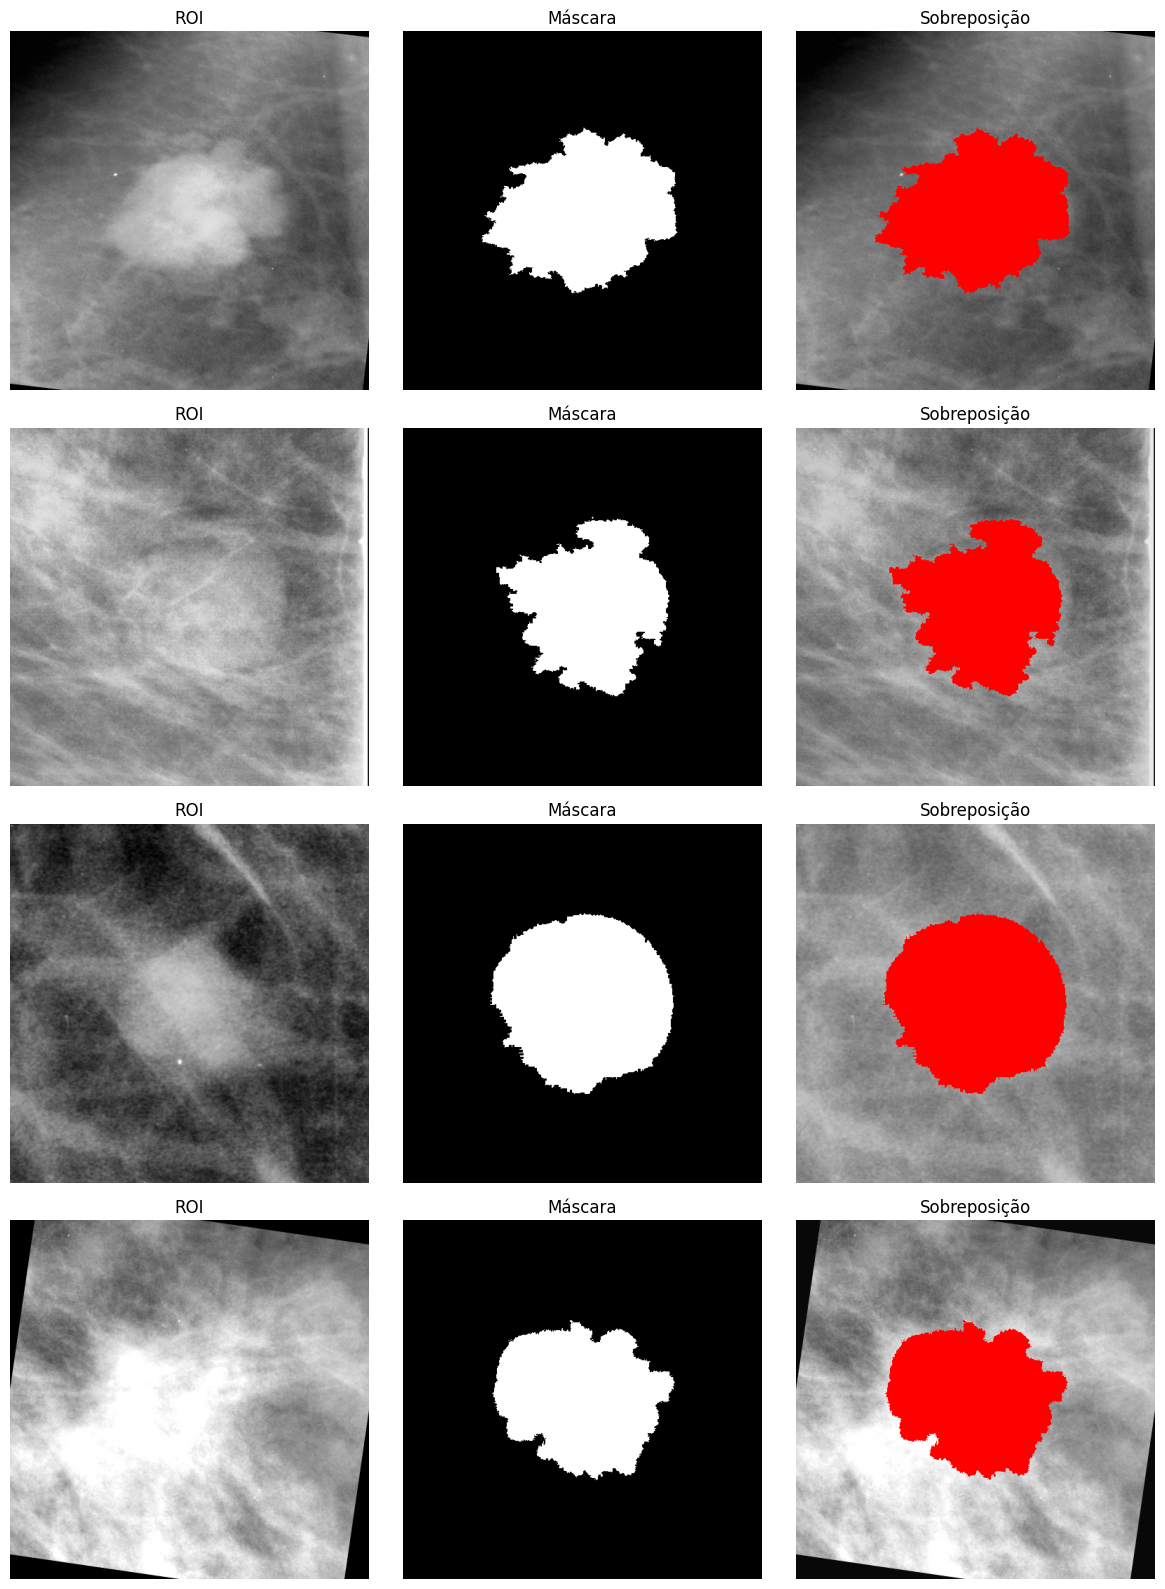

In [ ]:
# 10) Conferência visual das ROIs
fig, axes = plt.subplots(min(4,len(x_check)),3,figsize=(12,4*min(4,len(x_check))))
if len(x_check)==1: axes=np.expand_dims(axes,0)
for i in range(min(4,len(x_check))):
    im=x_check[i,...,0]/255.0; mk=y_check[i,...,0]>.5
    ov=np.dstack([im,im,im]); ov[mk]=[1,0,0]
    axes[i,0].imshow(im,cmap='gray'); axes[i,0].set_title('ROI')
    axes[i,1].imshow(mk,cmap='gray'); axes[i,1].set_title('Máscara')
    axes[i,2].imshow(ov); axes[i,2].set_title('Sobreposição')
    for ax in axes[i]: ax.axis('off')
plt.tight_layout()

In [ ]:
# 11) Métricas, loss e EfficientNetB0 U-Net
EPS=1e-6

@tf.keras.utils.register_keras_serializable(package='TCC_ROI')
def soft_dice(y_true,y_pred):
    y_true=tf.cast(y_true,tf.float32); y_pred=tf.cast(y_pred,tf.float32)
    inter=tf.reduce_sum(y_true*y_pred,axis=(1,2,3)); den=tf.reduce_sum(y_true+y_pred,axis=(1,2,3))
    return tf.reduce_mean((2*inter+EPS)/(den+EPS))

@tf.keras.utils.register_keras_serializable(package='TCC_ROI')
def hard_dice(y_true,y_pred):
    return soft_dice(y_true,tf.cast(y_pred>=.5,tf.float32))

@tf.keras.utils.register_keras_serializable(package='TCC_ROI')
def combined_loss(y_true,y_pred):
    y_true=tf.cast(y_true,tf.float32); y_pred=tf.cast(y_pred,tf.float32)
    bce=tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true,y_pred))
    tp=tf.reduce_sum(y_true*y_pred,axis=(1,2,3)); fp=tf.reduce_sum((1-y_true)*y_pred,axis=(1,2,3)); fn=tf.reduce_sum(y_true*(1-y_pred),axis=(1,2,3))
    tversky=(tp+1)/(tp+.35*fp+.65*fn+1)
    return .30*bce+.70*tf.reduce_mean(tf.pow(1-tversky,.75))

def conv_block(x,filters,name):
    for i in (1,2):
        x=layers.Conv2D(filters,3,padding='same',use_bias=False,kernel_initializer='he_normal',name=f'{name}_conv{i}')(x)
        x=layers.BatchNormalization(name=f'{name}_bn{i}')(x)
        x=layers.Activation('swish',name=f'{name}_act{i}')(x)
    return x

def build_model():
    inputs=keras.Input((ROI_SIZE,ROI_SIZE,3),name='roi')
    encoder=tf.keras.applications.EfficientNetB0(include_top=False,weights='imagenet',input_tensor=inputs)
    skips=[encoder.get_layer(n).output for n in ['stem_activation','block2a_activation','block3a_activation','block4a_activation']]
    x=encoder.get_layer('top_activation').output
    for skip,filters,name in zip(reversed(skips),[256,128,64,32],['dec4','dec3','dec2','dec1']):
        x=layers.UpSampling2D(2,interpolation='bilinear',name=name+'_up')(x)
        x=layers.Concatenate(name=name+'_cat')([x,skip])
        x=conv_block(x,filters,name)
    x=layers.UpSampling2D(2,interpolation='bilinear',name='final_up')(x)
    x=conv_block(x,16,'final')
    outputs=layers.Conv2D(1,1,activation='sigmoid',dtype='float32',name='mask')(x)
    return keras.Model(inputs,outputs,name='EfficientNetB0_UNet_ROI')

tf.keras.backend.clear_session()
model=build_model()
model.compile(tf.keras.optimizers.AdamW(LEARNING_RATE,weight_decay=1e-5,clipnorm=1.0),loss=combined_loss,metrics=[soft_dice,hard_dice])
model.summary()

Model: "EfficientNetB0_UNet_ROI"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ roi (InputLayer)    │ (None, 512, 512,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 512, 512,  │          0 │ roi[0][0]         │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 512, 512,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 512, 512,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 513, 513,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 256, 256,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 256, 256,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 256, 256,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 256, 256,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 256, 256,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 256, 256,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 256, 256,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 256, 256,  │        512 │ block1a_se_excit

 Total params: 8,963,380 (34.19 MB)

 Trainable params: 8,919,373 (34.02 MB)

 Non-trainable params: 44,007 (171.91 KB)

In [ ]:
# 12) Treinamento e salvamento do melhor Hard Dice de validação
BEST_WEIGHTS=RUN_DIR/'melhor_modelo_roi.weights.h5'
FINAL_WEIGHTS=RUN_DIR/'modelo_final_roi.weights.h5'
HISTORY_CSV=RUN_DIR/'historico_roi.csv'
if RESUME_FROM_BEST and BEST_WEIGHTS.exists():
    model.load_weights(BEST_WEIGHTS); print('Pesos ROI carregados:',BEST_WEIGHTS)

callbacks=[
    tf.keras.callbacks.ModelCheckpoint(str(BEST_WEIGHTS),monitor='val_hard_dice',mode='max',save_best_only=True,save_weights_only=True,verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_hard_dice',mode='max',factor=.5,patience=6,min_lr=1e-6,verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_hard_dice',mode='max',patience=16,restore_best_weights=True,verbose=1),
    tf.keras.callbacks.CSVLogger(str(HISTORY_CSV),append=RESUME_FROM_BEST),
    tf.keras.callbacks.TerminateOnNaN(),
]
history=model.fit(train_seq,validation_data=val_seq,epochs=EPOCHS,callbacks=callbacks,verbose=1)
model.save_weights(FINAL_WEIGHTS)
print('Melhor checkpoint ROI:',BEST_WEIGHTS)

Epoch 1/70
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - hard_dice: 0.5652 - loss: 0.5925 - soft_dice: 0.3965
Epoch 1: val_hard_dice improved from None to 0.49703, saving model to /content/drive/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas/melhor_modelo_roi.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas/melhor_modelo_roi.weights.h5
221/221 ━━━━━━━━━━━━━━━━━━━━ 691s 3s/step - hard_dice: 0.7045 - loss: 0.5098 - soft_dice: 0.4703 - val_hard_dice: 0.4970 - val_loss: 0.9275 - val_soft_dice: 0.4010 - learning_rate: 1.0000e-04
Epoch 2/70
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - hard_dice: 0.8385 - loss: 0.4110 - soft_dice: 0.5619
Epoch 2: val_hard_dice improved from 0.49703 to 0.79704, saving model to /content/drive/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-

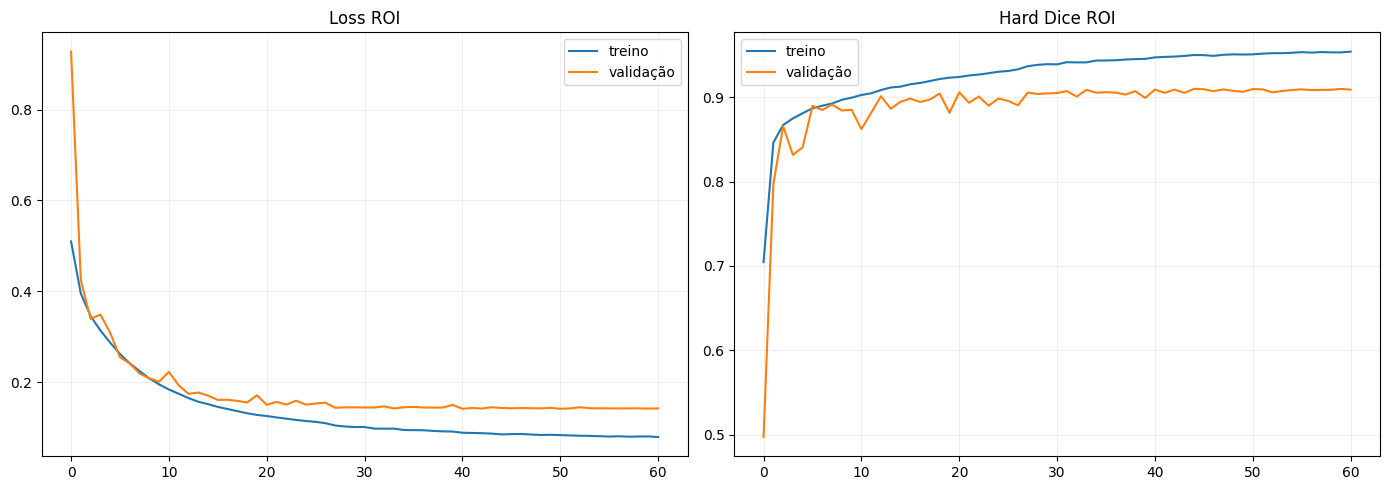

In [ ]:
# 13) Curvas do treinamento ROI
hist=pd.read_csv(HISTORY_CSV)
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].plot(hist.loss,label='treino'); axes[0].plot(hist.val_loss,label='validação'); axes[0].set_title('Loss ROI'); axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].plot(hist.hard_dice,label='treino'); axes[1].plot(hist.val_hard_dice,label='validação'); axes[1].set_title('Hard Dice ROI'); axes[1].legend(); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.savefig(RUN_DIR/'curvas_treinamento_roi.png',dpi=160,bbox_inches='tight'); plt.show()

In [ ]:
# 14) Predição e métricas de ROI
if BEST_WEIGHTS.exists(): model.load_weights(BEST_WEIGHTS)

def predict_roi(row):
    image,mask,meta=load_roi_pair(row.image_path,row.mask_path)
    x=np.repeat(image[...,None],3,axis=-1).astype(np.float32)[None]
    prob=model.predict(x,verbose=0)[0,...,0]
    return image,mask.astype(bool),prob,meta

def metrics_np(gt,pred):
    gt=gt.astype(bool); pred=pred.astype(bool)
    tp=np.logical_and(gt,pred).sum(); fp=np.logical_and(~gt,pred).sum(); fn=np.logical_and(gt,~pred).sum(); tn=np.logical_and(~gt,~pred).sum()
    return {'dice':2*tp/max(1,2*tp+fp+fn),'iou':tp/max(1,tp+fp+fn),'precision':tp/max(1,tp+fp),'sensitivity':tp/max(1,tp+fn),'specificity':tn/max(1,tn+fp),'intersection':int(tp),'true_pixels':int(gt.sum()),'pred_pixels':int(pred.sum())}

In [ ]:
# 15) Escolher o limiar somente na validação
thresholds=np.round(np.arange(.20,.81,.025),3)
scores={float(t):[] for t in thresholds}
for row in tqdm(val_df.itertuples(index=False),total=len(val_df),desc='Limiar ROI'):
    _,gt,prob,_=predict_roi(row)
    for t in thresholds: scores[float(t)].append(metrics_np(gt,prob>=t)['dice'])
grid_df=pd.DataFrame([{'threshold':t,'mean_dice':np.mean(v),'median_dice':np.median(v),'std_dice':np.std(v)} for t,v in scores.items()]).sort_values('mean_dice',ascending=False)
BEST_THRESHOLD=float(grid_df.iloc[0].threshold)
display(grid_df.head(10)); print('Melhor limiar ROI:',BEST_THRESHOLD)
grid_df.to_csv(RUN_DIR/'busca_limiar_roi.csv',index=False)

Limiar ROI:   0%|          | 0/190 [00:00<?, ?it/s]

,threshold,mean_dice,median_dice,std_dice
24,0.800,0.910613,0.919524,0.041243
23,0.775,0.910568,0.919482,0.041312
22,0.750,0.910506,0.919769,0.041404
21,0.725,0.910420,0.920275,0.041492
20,0.700,0.910337,0.920151,0.041572
19,0.675,0.910245,0.920077,0.041651
18,0.650,0.910149,0.919633,0.041738
17,0.625,0.910054,0.919182,0.041822
16,0.600,0.909955,0.919153,0.041897
15,0.575,0.909850,0.919340,0.041970


Melhor limiar ROI: 0.8


In [ ]:
# 16) Teste final das ROIs
prediction_dir=RUN_DIR/'predicoes_roi_teste'; prediction_dir.mkdir(exist_ok=True)
rows=[]
for i,row in enumerate(tqdm(test_df.itertuples(index=False),total=len(test_df),desc='Teste ROI')):
    image,gt,prob,meta=predict_roi(row); pred=prob>=BEST_THRESHOLD
    result=metrics_np(gt,pred); result.update(filename=row.filename,patient=row.patient,pathology=row.pathology,view=row.view,threshold=BEST_THRESHOLD,roi_scale=ROI_SCALE)
    rows.append(result)
    if i<SAVE_TEST_PREDICTIONS:
        cv2.imwrite(str(prediction_dir/f'{Path(row.filename).stem}_pred.png'),pred.astype(np.uint8)*255)
        cv2.imwrite(str(prediction_dir/f'{Path(row.filename).stem}_prob.png'),np.clip(prob*255,0,255).astype(np.uint8))
results_df=pd.DataFrame(rows); results_df.to_csv(RUN_DIR/'metricas_roi_por_imagem.csv',index=False)
micro=2*results_df.intersection.sum()/max(1,results_df.true_pixels.sum()+results_df.pred_pixels.sum())
summary={'task':'segmentação em ROI de referência','n_images':len(results_df),'n_patients':test_df.patient.nunique(),'roi_scale':ROI_SCALE,'threshold':BEST_THRESHOLD,'macro_dice_mean':results_df.dice.mean(),'macro_dice_std':results_df.dice.std(),'macro_dice_median':results_df.dice.median(),'micro_dice':micro,'mean_iou':results_df.iou.mean(),'mean_precision':results_df.precision.mean(),'mean_sensitivity':results_df.sensitivity.mean(),'mean_specificity':results_df.specificity.mean()}
summary={k:(v.item() if hasattr(v,'item') else v) for k,v in summary.items()}
with open(RUN_DIR/'resumo_teste_roi.json','w',encoding='utf-8') as f: json.dump(summary,f,ensure_ascii=False,indent=2)
print(json.dumps(summary,ensure_ascii=False,indent=2))

Teste ROI:   0%|          | 0/181 [00:00<?, ?it/s]

{
  "task": "segmentação em ROI de referência",
  "n_images": 181,
  "n_patients": 99,
  "roi_scale": 2.0,
  "threshold": 0.8,
  "macro_dice_mean": 0.9070870121659278,
  "macro_dice_std": 0.0593614338895179,
  "macro_dice_median": 0.9212978109042288,
  "micro_dice": 0.9124791356492001,
  "mean_iou": 0.8345980044914223,
  "mean_precision": 0.90274463425759,
  "mean_sensitivity": 0.918348179663886,
  "mean_specificity": 0.9849455609753031
}


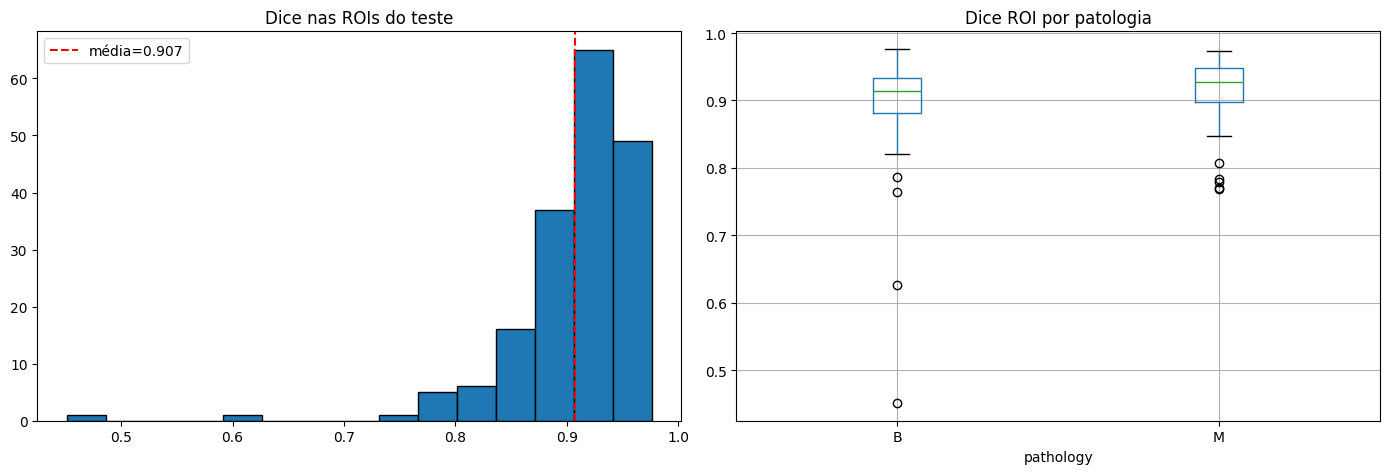

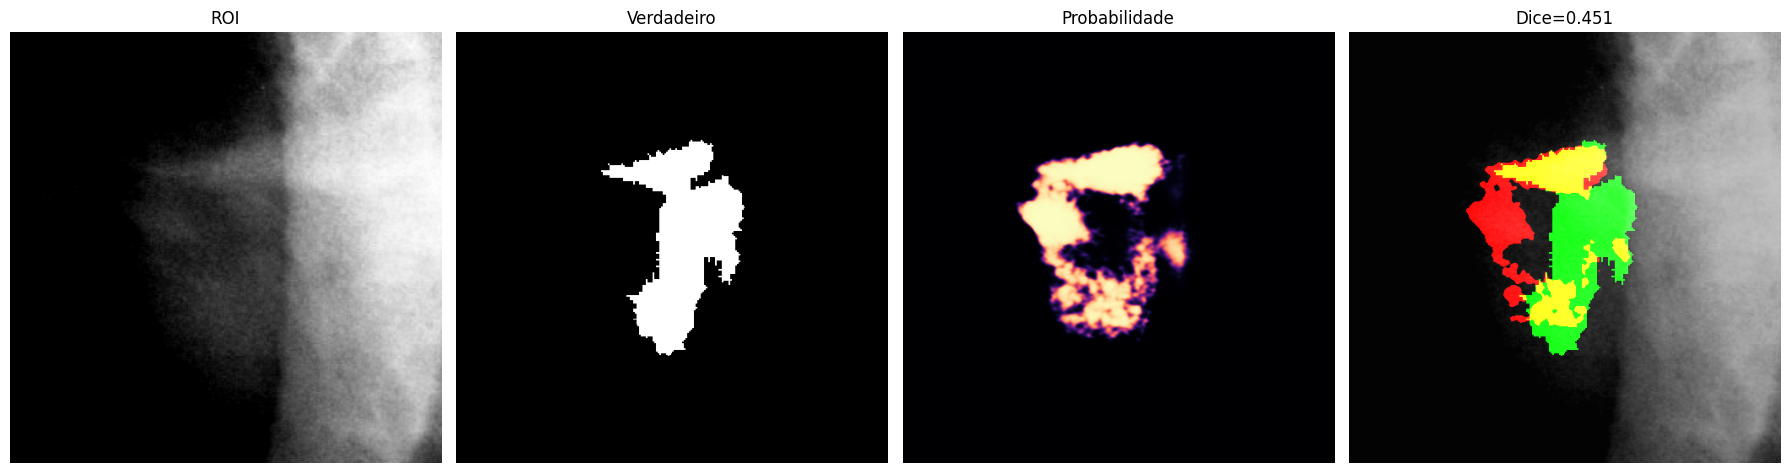

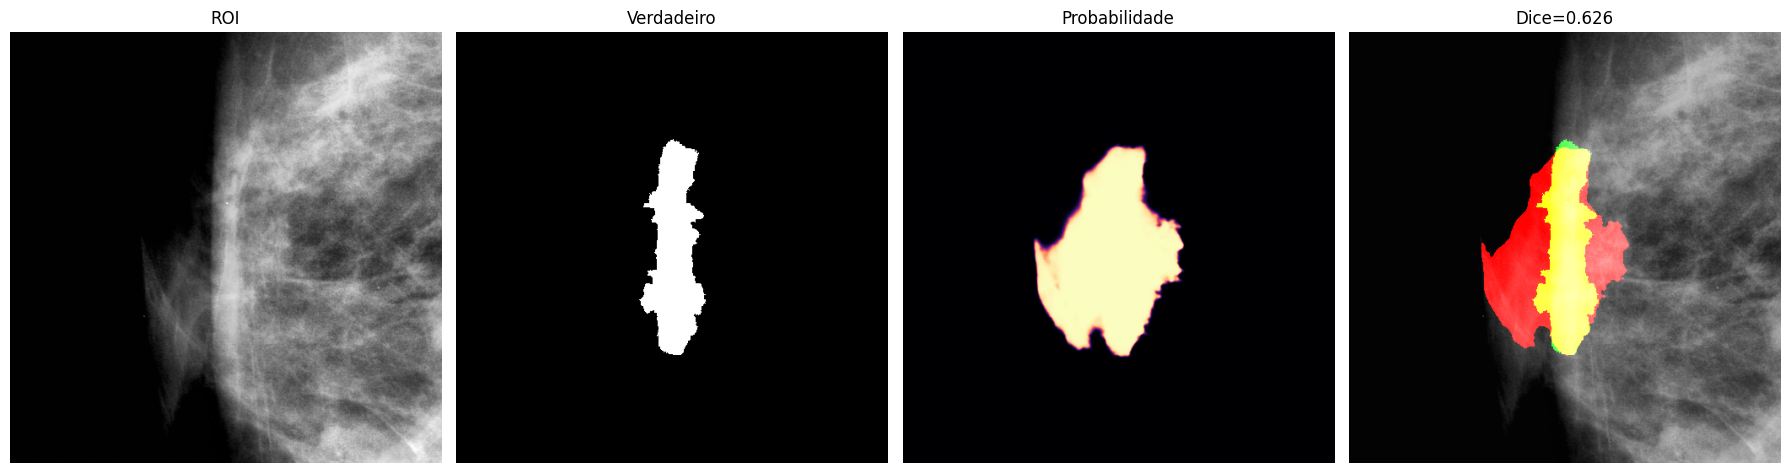

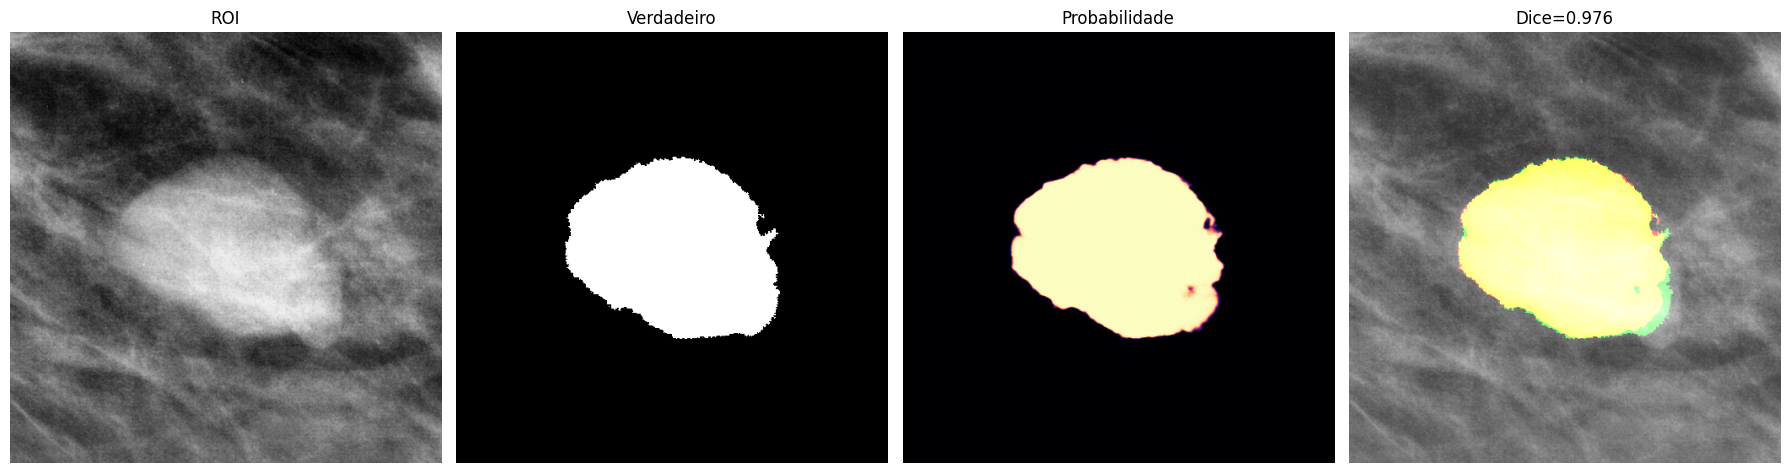

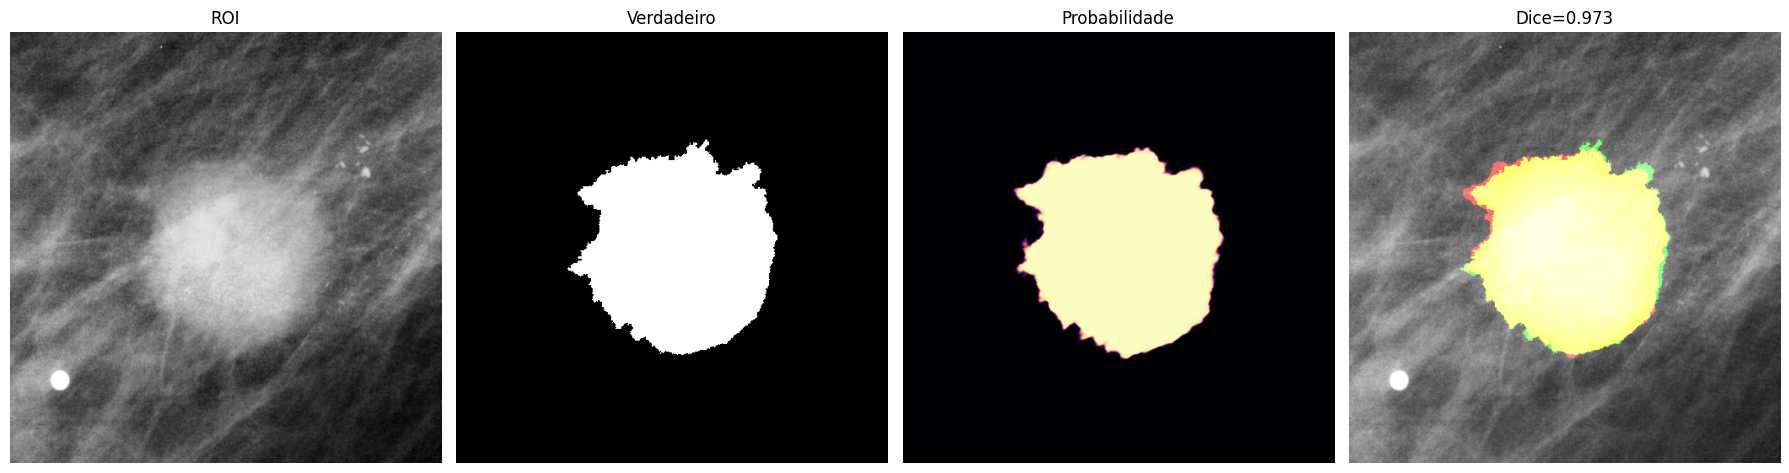

In [ ]:
# 17) Distribuição e exemplos visuais
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].hist(results_df.dice,bins=15,edgecolor='black'); axes[0].axvline(results_df.dice.mean(),color='red',ls='--',label=f'média={results_df.dice.mean():.3f}'); axes[0].legend(); axes[0].set_title('Dice nas ROIs do teste')
results_df.boxplot(column='dice',by='pathology',ax=axes[1]); axes[1].set_title('Dice ROI por patologia'); plt.suptitle('')
plt.tight_layout(); plt.savefig(RUN_DIR/'distribuicao_dice_roi.png',dpi=160,bbox_inches='tight'); plt.show()

for filename in pd.concat([results_df.nsmallest(2,'dice'),results_df.nlargest(2,'dice')]).filename:
    row=test_df[test_df.filename==filename].iloc[0]; image,gt,prob,_=predict_roi(row); pred=prob>=BEST_THRESHOLD
    ov=cv2.cvtColor(image,cv2.COLOR_GRAY2RGB).astype(np.float32)/255; ov[gt,1]=1; ov[pred,0]=1
    fig,ax=plt.subplots(1,4,figsize=(18,5)); ax[0].imshow(image,cmap='gray'); ax[1].imshow(gt,cmap='gray'); ax[2].imshow(prob,cmap='magma',vmin=0,vmax=1); ax[3].imshow(ov)
    for a,t in zip(ax,['ROI','Verdadeiro','Probabilidade',f'Dice={metrics_np(gt,pred)["dice"]:.3f}']): a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

In [ ]:
from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/"
    "2026_TCC_JoaoPedro_Segmentacao_Mamografias/"
    "02_DESENVOLVIMENTO/CBIS-DDSM/"
    "dataset_processed"
)

RUN_DIR = DATASET_DIR / "resultados_roi_massas"
BASE_DIR = RUN_DIR

print("Drive já montado.")
print("Pasta de resultados:", RUN_DIR)
print("Pasta existe:", RUN_DIR.exists())

print("\nArquivos encontrados:")
for arquivo in sorted(RUN_DIR.iterdir()):
    print("-", arquivo.name)

Drive já montado.
Pasta de resultados: /content/drive/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas
Pasta existe: True

Arquivos encontrados:
- graficos_tcc


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/gdrive_tcc")

Mounted at /content/gdrive_tcc


In [ ]:
BASE_DIR = Path(
    "/content/gdrive_tcc/MyDrive/"
    "2026_TCC_JoaoPedro_Segmentacao_Mamografias/"
    "02_DESENVOLVIMENTO/CBIS-DDSM/"
    "dataset_processed/resultados_roi_massas"
)

RUN_DIR = BASE_DIR
GRAFICOS_DIR = BASE_DIR / "graficos_tcc"
GRAFICOS_DIR.mkdir(exist_ok=True)

print("Pasta existe:", BASE_DIR.exists())
print("Pasta utilizada:", BASE_DIR)

print("\nArquivos encontrados:")

for arquivo in sorted(BASE_DIR.iterdir()):
    print("-", arquivo.name)

Pasta existe: True
Pasta utilizada: /content/gdrive_tcc/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas

Arquivos encontrados:
- auditoria_dataset.csv
- busca_limiar_roi.csv
- curvas_treinamento_roi.png
- distribuicao_dice_roi.png
- divisao_por_paciente.csv
- graficos_tcc
- historico_roi.csv
- manifesto_pares_validos.csv
- melhor_modelo_roi.weights.h5
- metricas_roi_por_imagem.csv
- modelo_final_roi.weights.h5
- predicoes_roi_teste
- resumo_teste_roi.json
- tcc1.png
- tcc2.png
- tcc3.png


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.read_csv(BASE_DIR / "historico_roi.csv")
threshold_df = pd.read_csv(BASE_DIR / "busca_limiar_roi.csv")
results_df = pd.read_csv(BASE_DIR / "metricas_roi_por_imagem.csv")

with open(
    BASE_DIR / "resumo_teste_roi.json",
    encoding="utf-8"
) as arquivo:
    summary = json.load(arquivo)

print("Resultados carregados corretamente.")
print(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nGráficos serão salvos em:", GRAFICOS_DIR)

Resultados carregados corretamente.
{
  "task": "segmentação em ROI de referência",
  "n_images": 181,
  "n_patients": 99,
  "roi_scale": 2.0,
  "threshold": 0.8,
  "macro_dice_mean": 0.9070870121659278,
  "macro_dice_std": 0.0593614338895179,
  "macro_dice_median": 0.9212978109042288,
  "micro_dice": 0.9124791356492001,
  "mean_iou": 0.8345980044914223,
  "mean_precision": 0.90274463425759,
  "mean_sensitivity": 0.918348179663886,
  "mean_specificity": 0.9849455609753031
}

Gráficos serão salvos em: /content/gdrive_tcc/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas/graficos_tcc


In [ ]:
# Gráficos

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = RUN_DIR

GRAFICOS_DIR = BASE_DIR / "graficos_tcc"
GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)

print("Lendo resultados de:", BASE_DIR)
print("\nArquivos encontrados:")

for arquivo in sorted(BASE_DIR.iterdir()):
    print("-", arquivo.name)

history_df = pd.read_csv(BASE_DIR / "historico_roi.csv")
threshold_df = pd.read_csv(BASE_DIR / "busca_limiar_roi.csv")
results_df = pd.read_csv(BASE_DIR / "metricas_roi_por_imagem.csv")

with open(
    BASE_DIR / "resumo_teste_roi.json",
    encoding="utf-8"
) as arquivo:
    summary = json.load(arquivo)

epochs = (
    history_df["epoch"] + 1
    if "epoch" in history_df.columns
    else np.arange(1, len(history_df) + 1)
)

best_threshold = float(summary["threshold"])
mean_dice = float(summary["macro_dice_mean"])
median_dice = float(summary["macro_dice_median"])

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120
})

def salvar_figura(nome):
    plt.savefig(
        GRAFICOS_DIR / f"{nome}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.savefig(
        GRAFICOS_DIR / f"{nome}.pdf",
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("\nResultados carregados corretamente.")
print("Gráficos serão salvos em:", GRAFICOS_DIR)

Lendo resultados de: /content/gdrive_tcc/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas

Arquivos encontrados:
- auditoria_dataset.csv
- busca_limiar_roi.csv
- curvas_treinamento_roi.png
- distribuicao_dice_roi.png
- divisao_por_paciente.csv
- graficos_tcc
- historico_roi.csv
- manifesto_pares_validos.csv
- melhor_modelo_roi.weights.h5
- metricas_roi_por_imagem.csv
- modelo_final_roi.weights.h5
- predicoes_roi_teste
- resumo_teste_roi.json
- tcc1.png
- tcc2.png
- tcc3.png

Resultados carregados corretamente.
Gráficos serão salvos em: /content/gdrive_tcc/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas/graficos_tcc


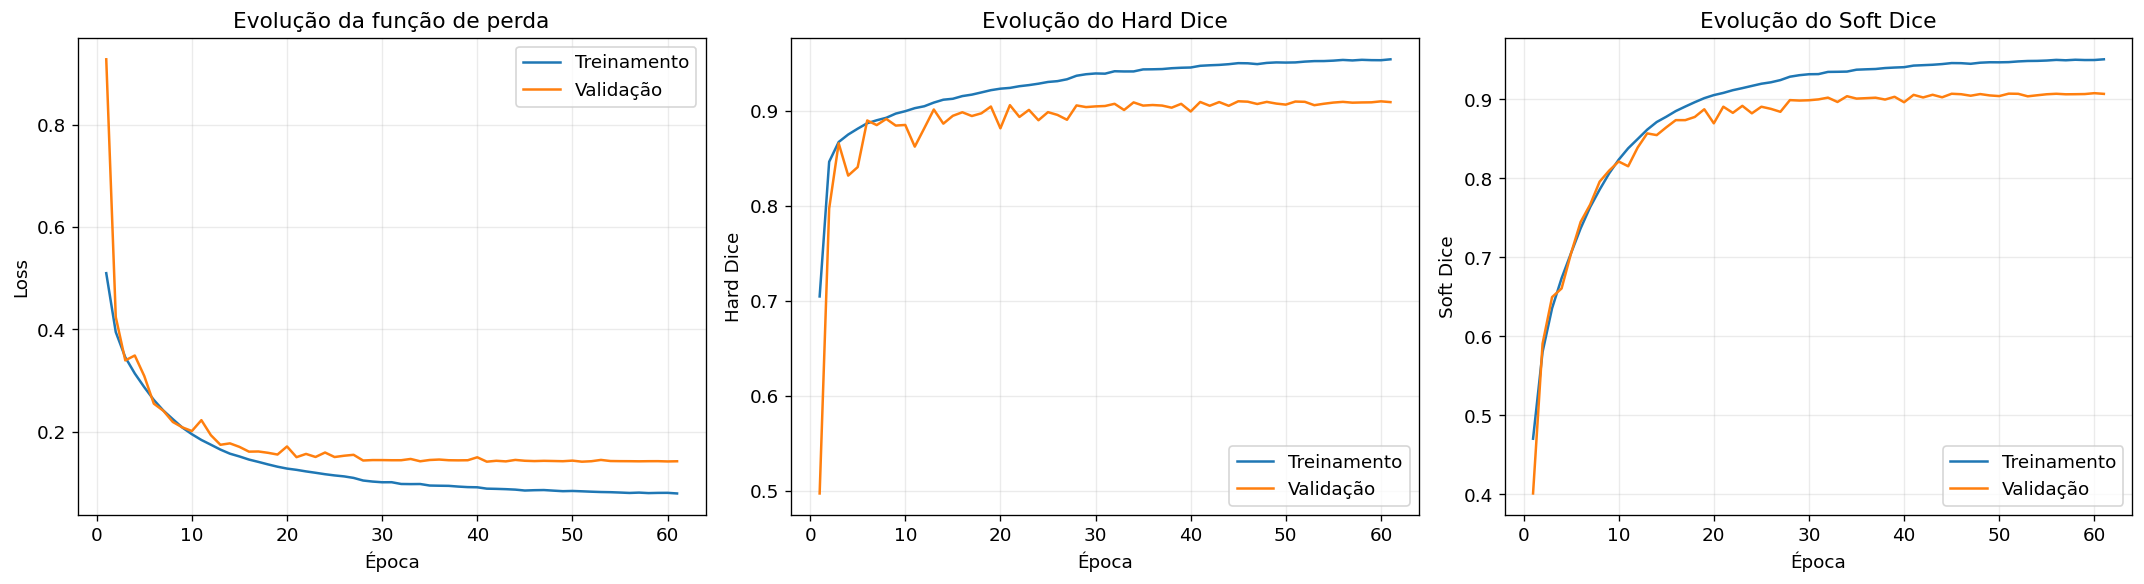

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs, history_df["loss"], label="Treinamento")
axes[0].plot(epochs, history_df["val_loss"], label="Validação")
axes[0].set_title("Evolução da função de perda")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs, history_df["hard_dice"], label="Treinamento")
axes[1].plot(epochs, history_df["val_hard_dice"], label="Validação")
axes[1].set_title("Evolução do Hard Dice")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Hard Dice")
axes[1].legend()
axes[1].grid(alpha=0.25)

axes[2].plot(epochs, history_df["soft_dice"], label="Treinamento")
axes[2].plot(epochs, history_df["val_soft_dice"], label="Validação")
axes[2].set_title("Evolução do Soft Dice")
axes[2].set_xlabel("Época")
axes[2].set_ylabel("Soft Dice")
axes[2].legend()
axes[2].grid(alpha=0.25)

plt.tight_layout()
salvar_figura("figura_01_curvas_treinamento")

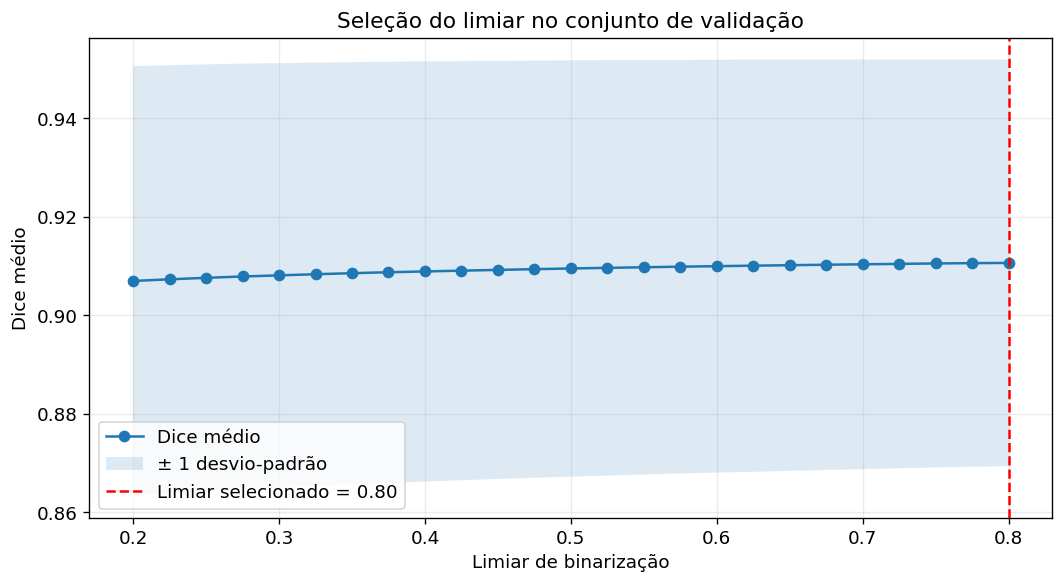

In [ ]:
threshold_plot = threshold_df.sort_values("threshold")

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    threshold_plot["threshold"],
    threshold_plot["mean_dice"],
    marker="o",
    label="Dice médio"
)

ax.fill_between(
    threshold_plot["threshold"],
    threshold_plot["mean_dice"] - threshold_plot["std_dice"],
    threshold_plot["mean_dice"] + threshold_plot["std_dice"],
    alpha=0.15,
    label="± 1 desvio-padrão"
)

ax.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Limiar selecionado = {best_threshold:.2f}"
)

ax.set_title("Seleção do limiar no conjunto de validação")
ax.set_xlabel("Limiar de binarização")
ax.set_ylabel("Dice médio")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
salvar_figura("figura_02_selecao_limiar")

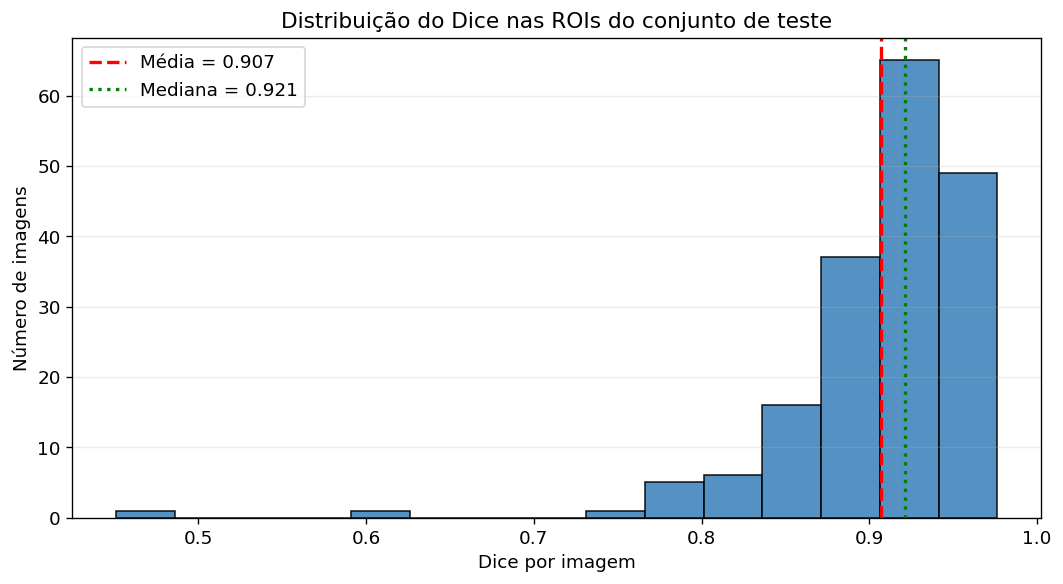

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    results_df["dice"],
    bins=15,
    color="#377eb8",
    edgecolor="black",
    alpha=0.85
)

ax.axvline(
    mean_dice,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Média = {mean_dice:.3f}"
)

ax.axvline(
    median_dice,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Mediana = {median_dice:.3f}"
)

ax.set_title("Distribuição do Dice nas ROIs do conjunto de teste")
ax.set_xlabel("Dice por imagem")
ax.set_ylabel("Número de imagens")
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
salvar_figura("figura_03_distribuicao_dice_teste")

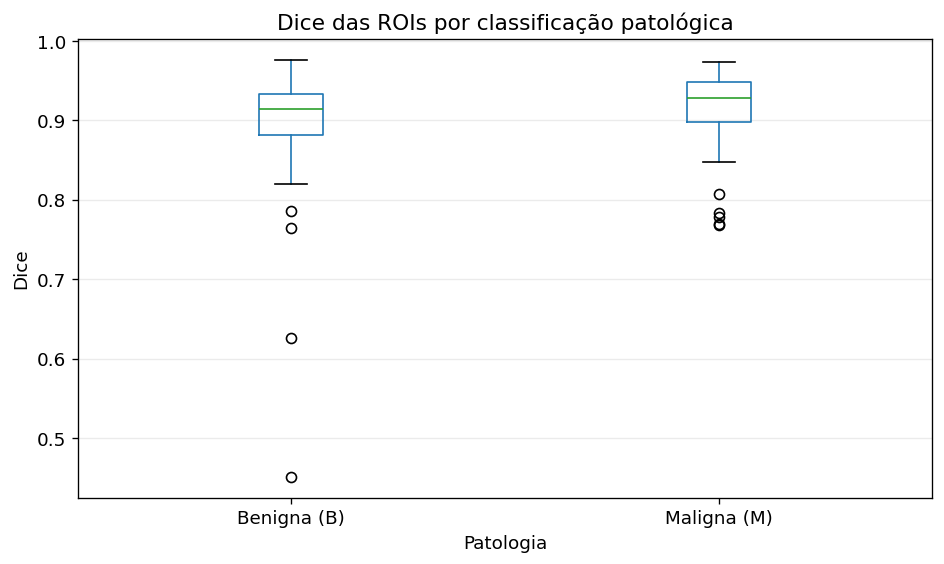

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

results_df.boxplot(
    column="dice",
    by="pathology",
    ax=ax,
    grid=False
)

ax.set_title("Dice das ROIs por classificação patológica")
ax.set_xlabel("Patologia")
ax.set_ylabel("Dice")
ax.set_xticklabels(["Benigna (B)", "Maligna (M)"])
ax.grid(axis="y", alpha=0.25)

plt.suptitle("")
plt.tight_layout()
salvar_figura("figura_04_dice_por_patologia")

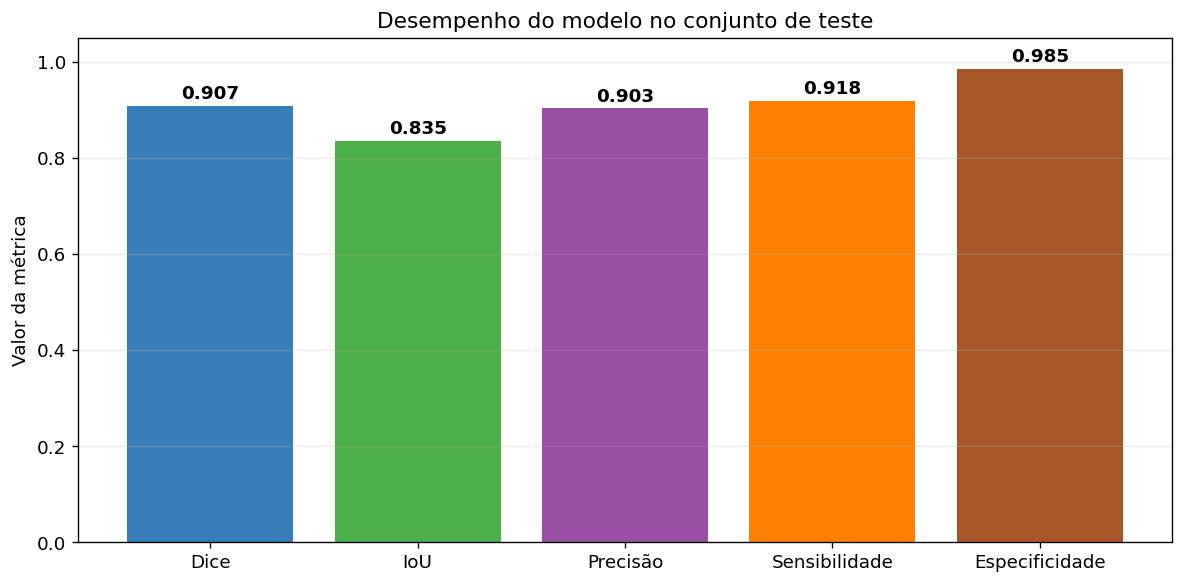

In [ ]:
metricas = {
    "Dice": summary["macro_dice_mean"],
    "IoU": summary["mean_iou"],
    "Precisão": summary["mean_precision"],
    "Sensibilidade": summary["mean_sensitivity"],
    "Especificidade": summary["mean_specificity"]
}

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    metricas.keys(),
    metricas.values(),
    color=["#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628"]
)

ax.set_ylim(0, 1.05)
ax.set_title("Desempenho do modelo no conjunto de teste")
ax.set_ylabel("Valor da métrica")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, metricas.values()):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
salvar_figura("figura_05_metricas_finais")

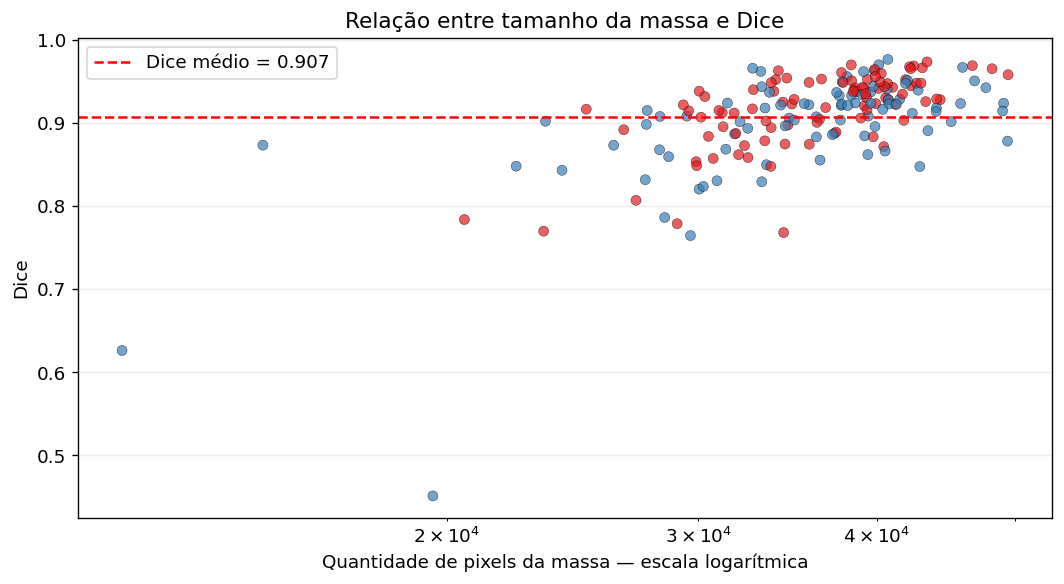

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

colors = results_df["pathology"].map({
    "B": "#377eb8",
    "M": "#e41a1c"
}).fillna("gray")

ax.scatter(
    results_df["true_pixels"],
    results_df["dice"],
    c=colors,
    alpha=0.70,
    edgecolor="black",
    linewidth=0.3
)

ax.axhline(
    mean_dice,
    color="red",
    linestyle="--",
    label=f"Dice médio = {mean_dice:.3f}"
)

ax.set_xscale("log")
ax.set_title("Relação entre tamanho da massa e Dice")
ax.set_xlabel("Quantidade de pixels da massa — escala logarítmica")
ax.set_ylabel("Dice")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
salvar_figura("figura_06_dice_por_tamanho_lesao")

In [ ]:
tabela_resultados = pd.DataFrame({
    "Métrica": [
        "Dice médio",
        "Desvio-padrão do Dice",
        "Dice mediano",
        "Dice global",
        "IoU médio",
        "Precisão",
        "Sensibilidade",
        "Especificidade",
        "Imagens de teste",
        "Pacientes de teste"
    ],
    "Resultado": [
        summary["macro_dice_mean"],
        summary["macro_dice_std"],
        summary["macro_dice_median"],
        summary["micro_dice"],
        summary["mean_iou"],
        summary["mean_precision"],
        summary["mean_sensitivity"],
        summary["mean_specificity"],
        summary["n_images"],
        summary["n_patients"]
    ]
})

display(tabela_resultados)

tabela_resultados.to_csv(
    GRAFICOS_DIR / "tabela_resultados_finais.csv",
    index=False
)

print("Gráficos salvos em:")
print(GRAFICOS_DIR)

,Métrica,Resultado
0,Dice médio,0.907087
1,Desvio-padrão do Dice,0.059361
2,Dice mediano,0.921298
3,Dice global,0.912479
4,IoU médio,0.834598
5,Precisão,0.902745
6,Sensibilidade,0.918348
7,Especificidade,0.984946
8,Imagens de teste,181.000000
9,Pacientes de teste,99.000000


Gráficos salvos em:
/content/gdrive_tcc/MyDrive/2026_TCC_JoaoPedro_Segmentacao_Mamografias/02_DESENVOLVIMENTO/CBIS-DDSM/dataset_processed/resultados_roi_massas/graficos_tcc


In [ ]:
# 18) Conferir os artefatos produzidos
for path in sorted(RUN_DIR.iterdir()):
    print(path.name)

auditoria_dataset.csv
busca_limiar_roi.csv
curvas_treinamento_roi.png
distribuicao_dice_roi.png
divisao_por_paciente.csv
historico_roi.csv
manifesto_pares_validos.csv
melhor_modelo_roi.weights.h5
metricas_roi_por_imagem.csv
modelo_final_roi.weights.h5
predicoes_roi_teste
resumo_teste_roi.json
